### Funzioni

In [236]:
import numpy as np
import matplotlib.pyplot as plt

In [237]:
def input_data(file, Arduino=False):

    if Arduino:
        t, V = np.loadtxt(file, unpack=True)
    else:
        t, _, V, _ = np.loadtxt(file, unpack=True)

    return t,V

In [238]:
def do_FFT(t,V, Arduino=False):
    N = len(V)
    dt = t[1] - t[0] 
    if Arduino: 
        dt= dt * 1e-6          #  Arduino prende in micros
    freq = np.fft.rfftfreq(N, d=dt)
    ASD = np.abs(np.fft.rfft(V))

    return freq, ASD

In [239]:
def peaks(freq, ASD):
    
    peak_indices = []

    for i in range(1, len(ASD)-1):
        if ASD[i] > ASD[i-1] and ASD[i] > ASD[i+1] and ASD[i] > 1:
            peak_indices.append(i)

    print('Peaks: \n')
    for i in peak_indices:
        print(freq[i], ASD[i])
    
    peak_freqs = [freq[i] for i in peak_indices]

    return peak_freqs

In [240]:
def plot_ASD(t,V, freq, ASD, peak_freqs, peak_idx, maxf, log=True):

    fig, axes = plt.subplots(nrows=2, ncols=1, constrained_layout=True, figsize = (12,6*2))
    
    axes[0].plot(t,V)
    axes[0].set_xlabel("Tempo [s]")
    axes[0].set_ylabel("Segnale [digit]")
    axes[0].grid()

    axes[1].plot(freq, ASD)
    axes[1].set_xlabel("Frequenza [Hz]")
    axes[1].set_ylabel("ASD [u.a.]")
    axes[1].grid()

    if log:
        axes[1].set_yscale("log")

    if maxf == None:
        maxf = peak_freqs[30]

    axes[1].set_xlim(0, maxf)

    if peak_idx != None:
        peak_freqs = [peak_freqs[i] for i in peak_idx]


    for p in peak_freqs:
        idx = np.argmin(np.abs(freq - p))
        axes[1].annotate(f"{p:.0f} Hz",
                    xy=(freq[idx], ASD[idx]),
                    xytext=(freq[idx] *1.1, ASD[idx] *1.1 ),
                    arrowprops=dict(arrowstyle='-', lw=0.8),
                    fontsize=9)
    
    plt.show()
    return

In [241]:
def do_all(file, Arduino=False, peak_idx=None, maxf=None, log=True):
    t,V = input_data(file, Arduino=Arduino)
    freq, ASD = do_FFT(t,V, Arduino=Arduino)
    peak_freqs= peaks(freq, ASD)
    plot_ASD(t,V,freq,ASD, peak_freqs, peak_idx, maxf, log=log)
    return

### Experiments

mancano da vedere quadre e triangolari prese con Arduino  

quando va messa asse y in log???  


In [242]:
dir = '/home/gea/Desktop/Lab_2/AliceGea/Esperienza_'

**Recap**

| Esperimento             | FFT                  |
| ----------------------- | -------------------- |
| sinusoide               | picco singolo        |
| diodo (piccolo segnale) | quasi picco singolo  |
| raddrizzatore           | molte armoniche + DC |
| autooscillatore         | picco + armoniche    |
| RLC smorzato            | picco largo continuo |


#### Raddrizzatore

Peaks: 

49.99750000000008 1089494.1147565972
99.99500000000016 21261.335664404498
106.24468750000017 9491.229489285626
153.11734375000026 7730.0648900716615
193.7403125000003 5097.811680838758
199.99000000000032 5403.429271836556
209.36453125000034 4145.409320755623
228.11359375000038 3973.57480289149
234.36328125000037 3864.979188990574
240.6129687500004 3703.3498294028414
253.1123437500004 3704.6072746346813
287.4856250000005 3055.492455564602
303.1098437500005 4295.463552133112
315.6092187500005 2827.095351808002
331.23343750000055 2732.4693946296693
343.73281250000053 2576.2653315329153
353.10734375000055 4001.001033008622
368.7315625000006 2385.3768026701955
378.1060937500006 2299.698921819616
387.4806250000006 2292.4028825221158
393.73031250000065 2327.7773526131314
406.22968750000064 2210.231165005393
415.60421875000065 2138.5466497002544
437.4781250000007 2000.1168685290716
456.22718750000075 2121.956323661978
474.9762500000008 1861.8590798181992
481.2259375000008 1923.5101693

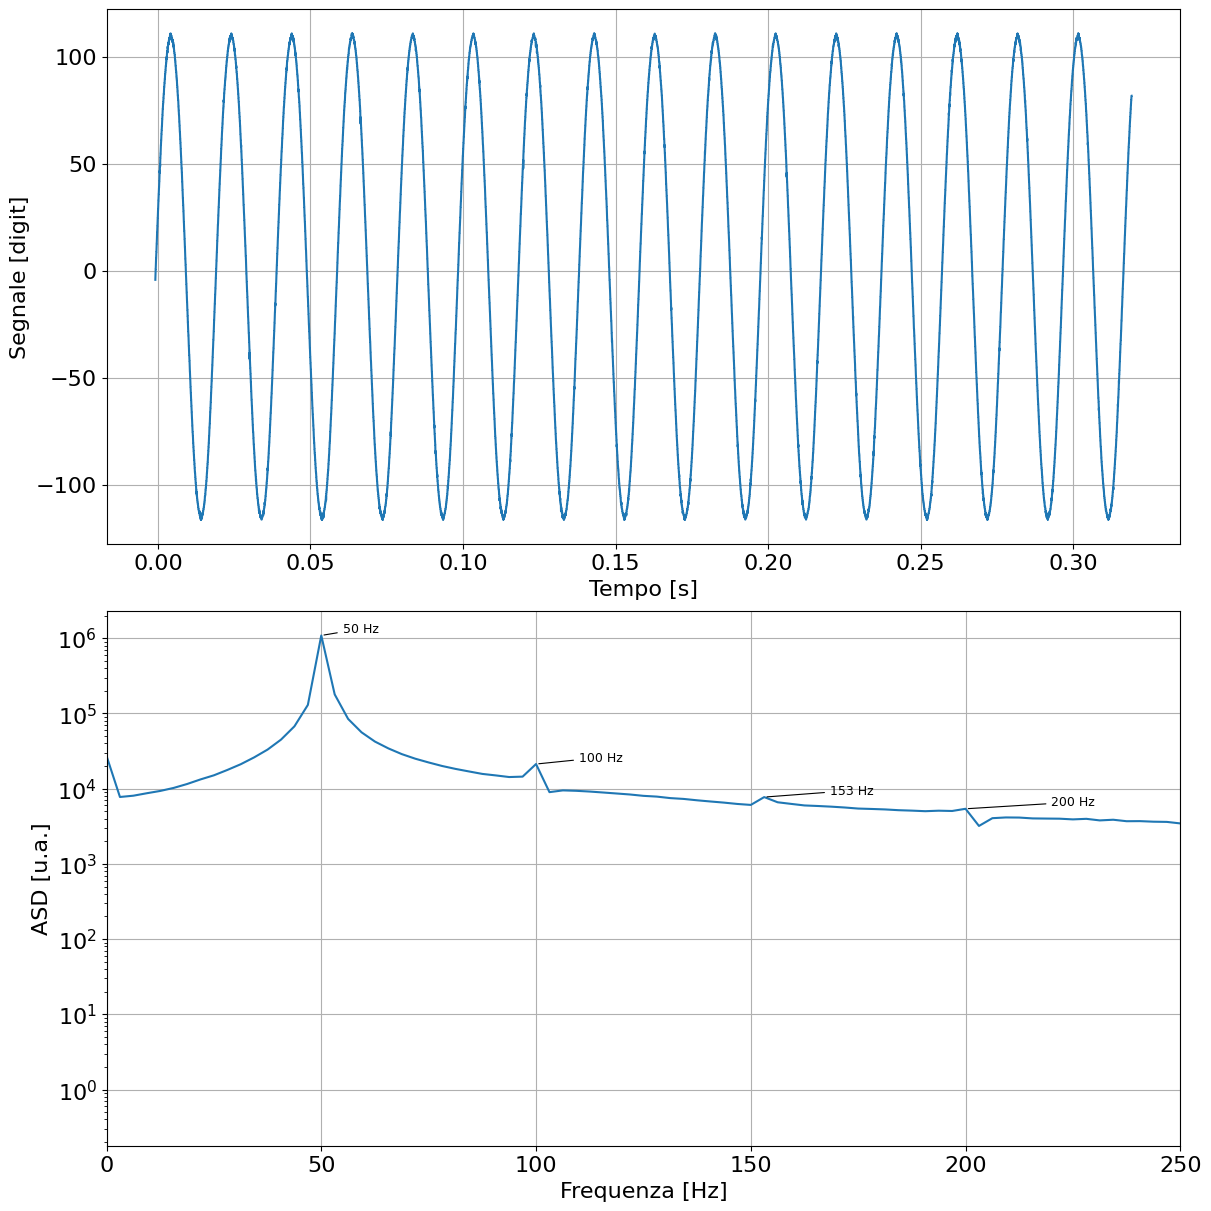

In [243]:
file = dir+'9/Livellatore/livellatore_senza_condensatore_CH1.txt'
idx = [0,1,3,5]
maxf = 250
do_all(file, Arduino=False, peak_idx=idx, maxf=maxf)

Peaks: 

49.99750000000008 905025.5072414124
99.99500000000016 550490.0377999957
149.99250000000023 215965.26881811017
199.99000000000032 37149.36398655521
215.61421875000033 4437.083691834543
221.86390625000035 4231.592693720631
253.1123437500004 35386.734015094626
274.98625000000044 5717.546663275186
303.1098437500005 29933.469905048336
318.7340625000005 4089.8726371344956
331.23343750000055 3953.3821887568674
337.48312500000054 3854.148326833652
346.85765625000056 3662.9066132414337
356.2321875000006 3285.111564582902
362.48187500000057 3377.5078258296767
368.7315625000006 3404.9971452730742
381.2309375000006 3271.0970008877725
390.6054687500006 3285.7967916919924
403.10484375000067 14739.034219444193
418.7290625000007 2694.60322687779
440.6029687500007 2404.529063782498
453.1023437500007 7664.368751451451
474.9762500000008 2735.2811703523157
484.3507812500008 2610.231983003479
506.2246875000008 3287.8574094917994
515.5992187500008 2603.607547659546
521.8489062500008 2442.0491893811

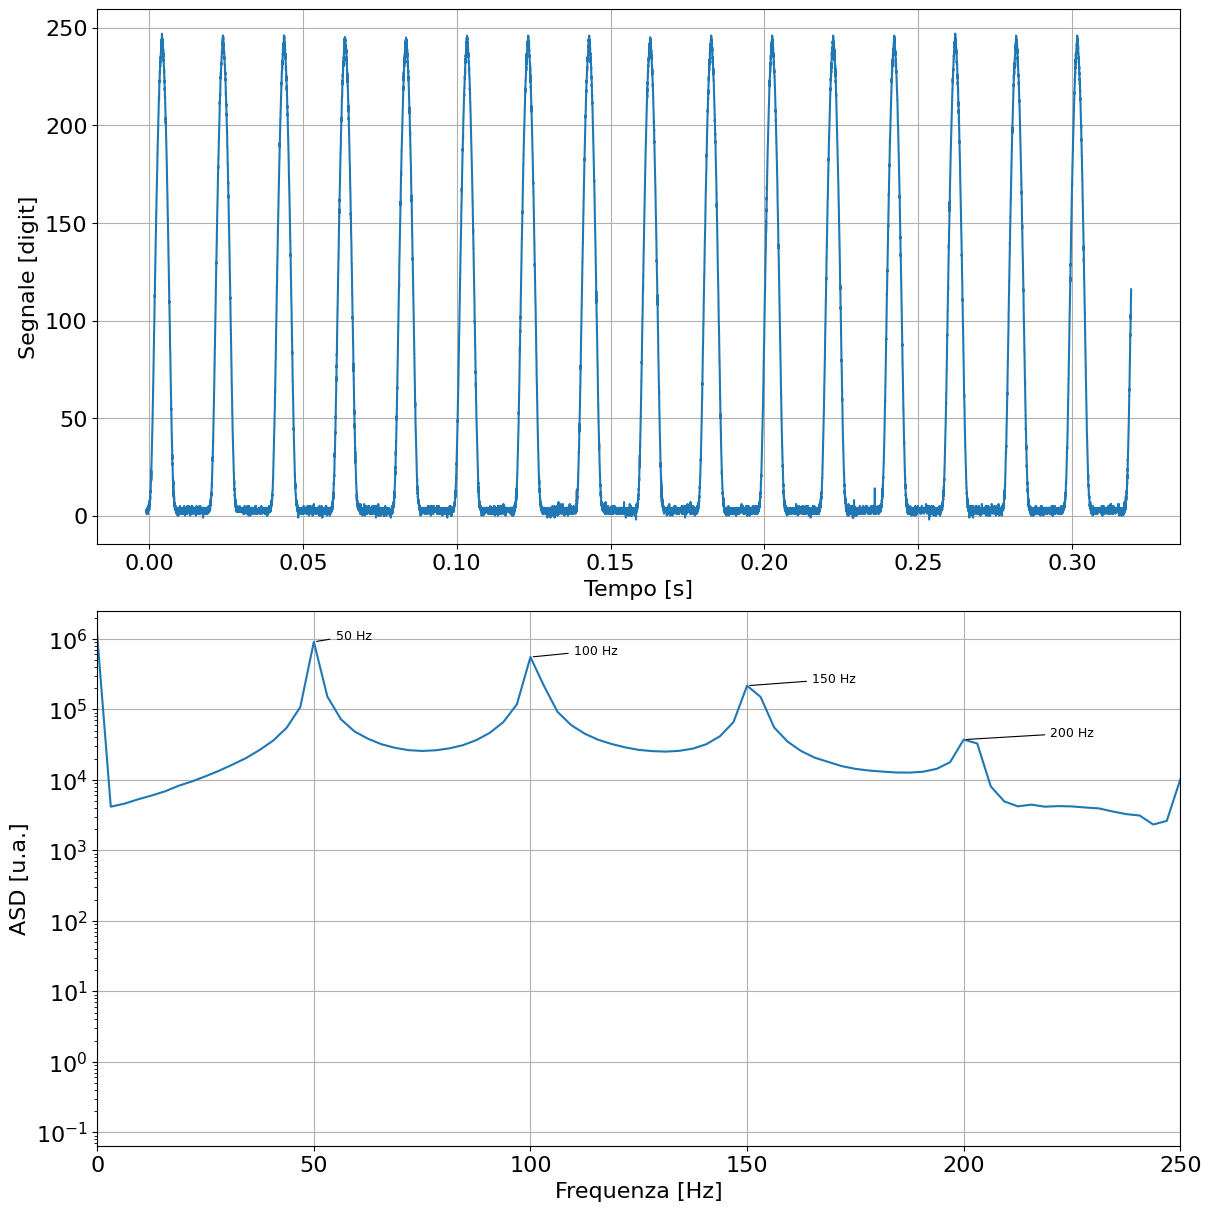

In [244]:
file = dir+'9/Livellatore/livellatore_senza_condensatore_CH2.txt'
idx = [0,1,2,3]
maxf = 250
do_all(file, Arduino=False, peak_idx=idx, maxf=maxf)

**Spiegazione**

segnale in ingresso:   
sinusoide pura (solo un po' sporca)    
picco a $f_0= 50 \, Hz$  

segnale in uscita:  
dopo raddrizzameto non è più sinusoidale  
1- compare una componente DC  
perchè il segnale non è più alternato (è sempre positivo, quindi valore medio non è 0)  
cioè c'è un picco a f=0  
2- compaiono armoniche  
perchè il segnale è “tagliato” (difficile da rappresentare) → ha spigoli → servono molte frequenze  
ci sono $f_0, \; 2f_0, \; 3f_0$...  
perchè sto deformando il segnale, quindi per descriverlo mi servono anche armoniche superiori (le sovrappongo tutte per avere segnali più complessi)  

infatti le armoniche superiori, vedi che prima sono bassissime, quasi inesistenti (è solo il segnale un po' sporco perchè il egneratore è reale)  
mentre dopo si vede bene che ci stanno  


#### Segnale livellato

PROBLEMA: L'HO PRESO MALE, NON È LIVELLATO PER NIENTE!!!

**Spiegazione**

in tempo:  
il segnale diventa quasi costante
con piccolo ripple  

In frequenza
picco enorme a f=0  
piccolo picco a:   
f0 (semionda)
2f0 (doppia semionda)  
io ho fatto semionda, NON doppia semionda  

✔️ Interpretazione  
👉 il condensatore è filtro passa-basso  
elimina alte frequenze  
lascia DC  

Peaks: 

9.374531250000015 4768.501692139412
15.624218750000026 5228.811934535755
49.99750000000008 250999.30573339594
74.99625000000012 5734.29431599901
99.99500000000016 95489.00259949814
121.8689062500002 4789.911276281489
128.1185937500002 3934.503863251299
149.99250000000023 38102.982558256466
171.86640625000027 3434.23892181881
187.4906250000003 3228.2792929342836
203.11484375000032 16174.111858600718
224.98875000000035 1610.0887462290216
237.4881250000004 1694.9778246860403
253.1123437500004 7761.683396046558
262.4868750000004 853.1059449491269
268.73656250000045 778.2112882914128
278.11109375000046 996.5698358261684
284.36078125000046 423.1304623178752
290.61046875000045 998.794813424506
303.1098437500005 2882.678327253864
318.7340625000005 852.5298683764491
324.9837500000005 537.1571311838562
337.48312500000054 639.6234323645316
346.85765625000056 495.39531987070944
365.6067187500006 602.5358253561127
374.9812500000006 844.1089145925373
384.35578125000063 467.8019788963539
390

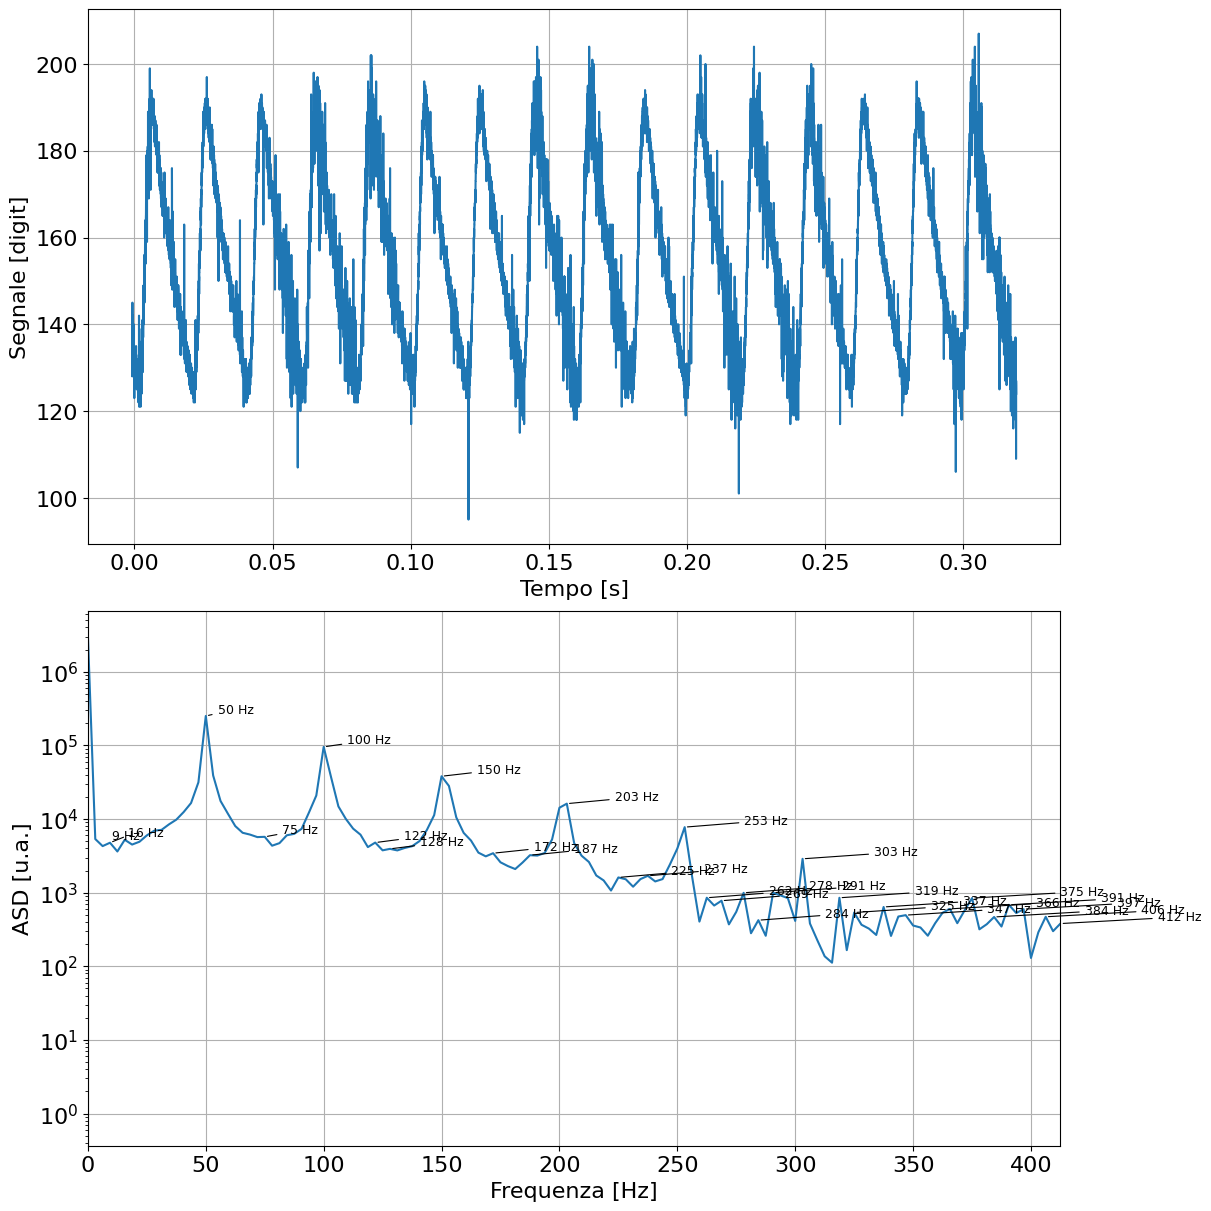

In [245]:
# Segnale livellato - NO!!!

file = dir+'9/Livellatore/livellatore_tanti_periodi_CH2.txt'
do_all(file, Arduino=False)

# NO, NON VA BENE, PERCHÈ NON È LIVELLATO, HO ASPETTATO TROPPO TEMPO E SI È SCARICATO, NON È PIATTO

# Analisi
# il condensatore filtra → resta DC + ripple

#### Resistenza diodo

Peaks: 

187.490625 4040.840194019346
1374.9312499999999 1098166.3395131193
2749.8624999999997 8158.062638375287
2937.3531249999996 5901.84910290116
3812.309375 4157.375685850866
4124.79375 5269.799544553142
4437.278125 3304.966305415417
4749.7625 3137.6294474075416
4874.756249999999 3054.5638637228376
5499.724999999999 4546.290233378785
5937.203125 2301.2495839262174
6124.693749999999 2265.303051870283
6249.6875 2116.518194744452
6374.68125 2107.602799720005
6624.66875 2024.8357612871603
6749.662499999999 2014.583101444753
6937.153125 2147.6116119512894
7187.140624999999 1892.3785883010312
7374.631249999999 1972.6169853601946
7499.624999999999 1800.1779675093708
7937.103125 1679.8855634500414
8062.096874999999 1739.1980220711753
8312.084374999999 1981.3556827744155
8499.574999999999 1614.8197306401369
8749.5625 1572.5286126998553
9062.046875 1485.5249311187358
9249.537499999999 1478.2282180727361
9374.53125 1428.18211435866
9687.015625 2342.743507495722
9937.003125 1407.7869749861386


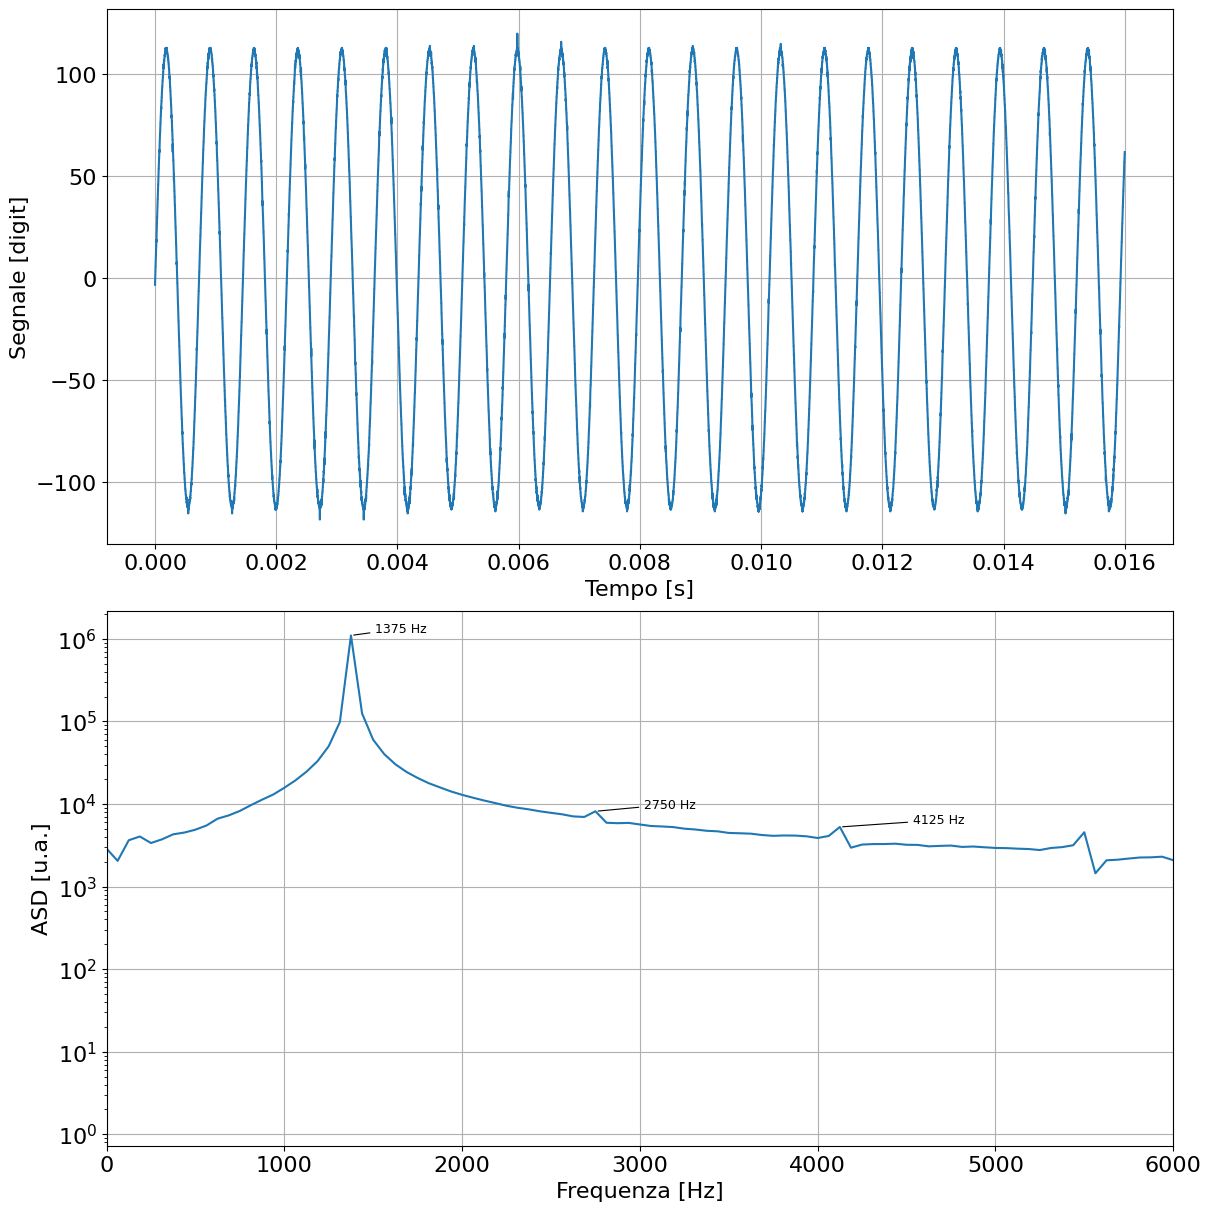

In [246]:
file = dir+'9/Resistenza_diodo/resistenza_diodo2_CH2.txt'
idx = [1,2,5]
maxf = 6000
do_all(file, Arduino=False, peak_idx=idx, maxf=maxf)

Peaks: 

249.98749999999998 4238.34143255308
437.478125 1771.496668972967
624.96875 2207.507783927605
812.4593749999999 2840.8085979638977
999.9499999999999 2760.684167790492
1124.94375 3918.8164589794596
1374.9312499999999 116600.50415502008
1687.4156249999999 3920.988251136258
1812.409375 3154.7196043686076
1999.8999999999999 4771.67828242327
2187.390625 2262.1165744123996
2312.3843749999996 3717.604956106125
2499.875 4425.259000199561
2812.359375 2455.3847226890266
2999.85 2398.6607578228354
3124.84375 2086.1049673420125
3249.8374999999996 2012.961423185312
3437.3281249999995 1798.9917602169173
3687.3156249999997 2357.363711358489
3812.309375 2771.3102397538346
3999.7999999999997 2371.849756368779
4249.787499999999 2393.310007518479
4374.78125 2929.5628600757204
4499.775 1796.2341510566835
4624.768749999999 1835.2048676535217
4749.7625 3039.872622960029
5062.246875 2981.989886319835
5312.234375 4018.712916032703
5499.724999999999 1981.756983780216
5749.7125 2088.617568243909
5999.7 

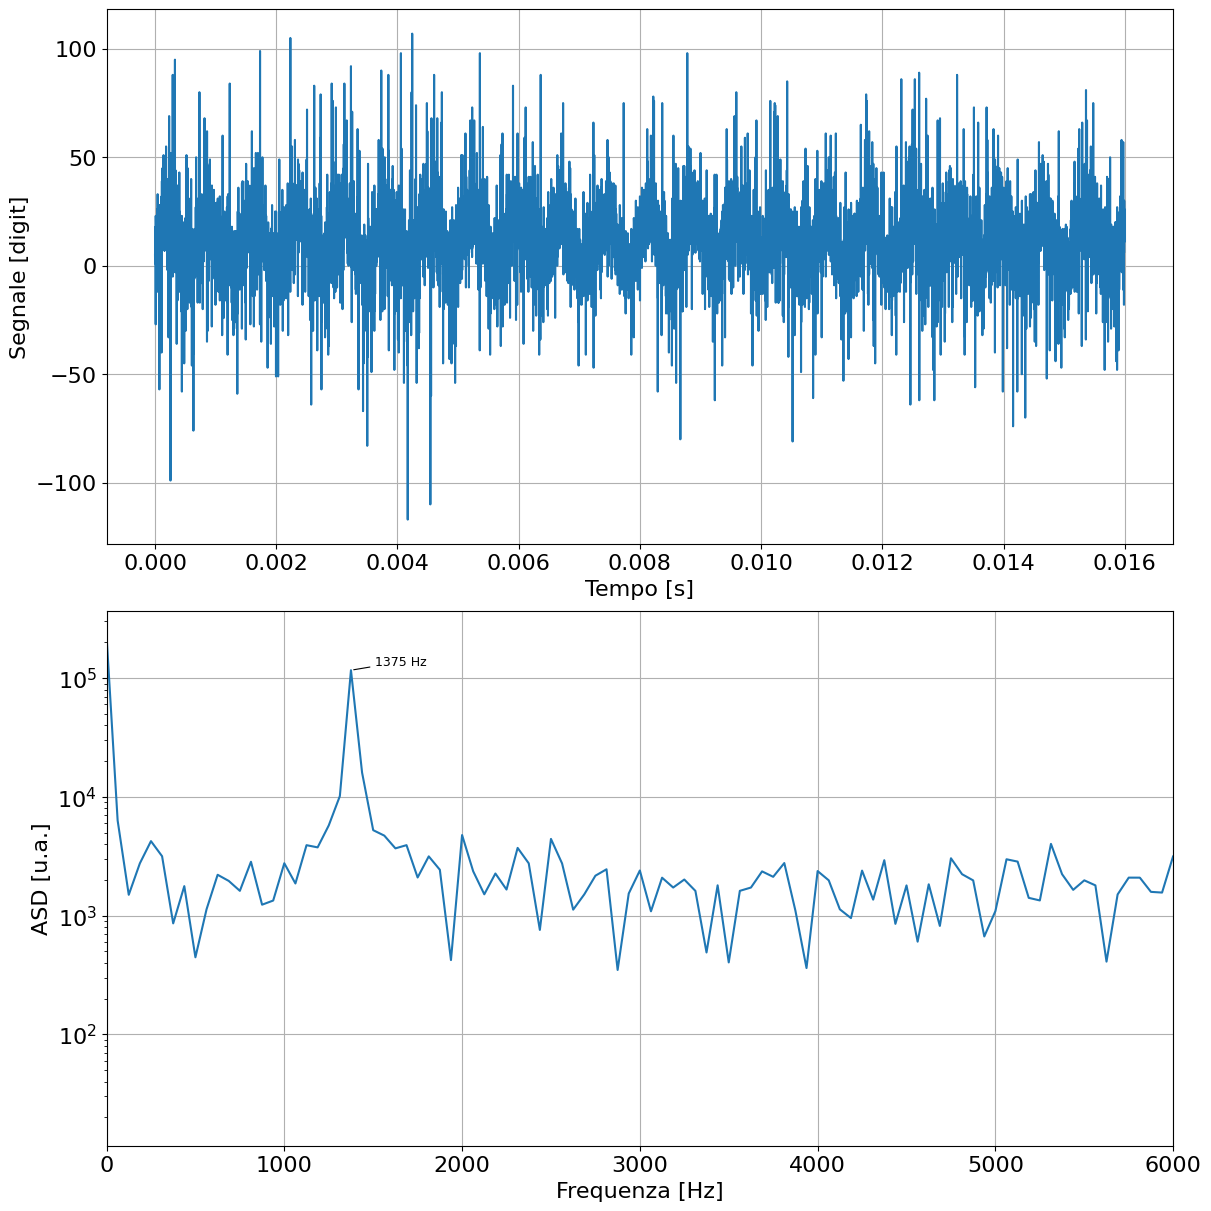

In [247]:
file = dir+'9/Resistenza_diodo/resistenza_diodo2_CH1.txt'
idx = [6]
maxf = 6000
do_all(file, Arduino=False, peak_idx=idx, maxf=maxf)

**Spiegazione**

segnale in ingresso:   
piccola oscillazione (attorno a un punto di lavoro)  

segnale in uscita:  
il diodo è non lineare, ma se l'oscillazione è piccola e non cambia il punto di lavoro, il comportamento è quasi lineare  
infatti vedo un solo picco alla $f_0$ di prima, come una sinusoide pura  
L'eventuale presenza di armoniche indica deviazioni dal comportamento lineare del dispositivo.

note:  
se vedi solo f0 → regime lineare (resistenza dinamica ben definita) (che vuol dire???)  
perchè è apparso offset???  

Nel regime di piccolo segnale, il diodo può essere approssimato come un elemento lineare, e lo spettro mostra un unico picco alla frequenza fondamentale. La presenza di armoniche indica deviazioni dal comportamento lineare, dovute alla natura esponenziale della caratteristica del diodo.  

#### Autooscillatore

Peaks: 

171.86640624999998 804484.9628687451
359.35703125 71924.8497042515
531.2234374999999 17811.901025974857
671.84140625 10746.251124681856
703.08984375 11692.971164513101
859.3320312499999 7453.063792731368
890.5804687499999 9346.669491232287
1078.0710937499998 6163.269280003873
1203.06484375 5205.909888310892
1234.3132812499998 5120.501107139524
1281.1859375 4711.642141632043
1343.6828125 4571.549134912436
1390.5554687499998 4362.846471313326
1437.428125 4284.701511215695
1515.54921875 4088.294071666176
1546.7976562499998 4006.8873367015153
1593.6703125 3922.455323949545
1640.54296875 3633.303311640234
1703.0398437499998 3518.8692956221544
1734.28828125 3486.152661162178
1781.1609374999998 3435.5636733583506
1812.409375 3292.042424829488
1843.6578124999999 3186.598459874952
1874.9062499999998 3207.879385685677
1968.6515625 3319.73404555507
2031.1484374999998 2948.9787309043404
2062.396875 2928.9247364493503
2124.8937499999997 2802.955388034181
2187.390625 2821.899809382123
2249.

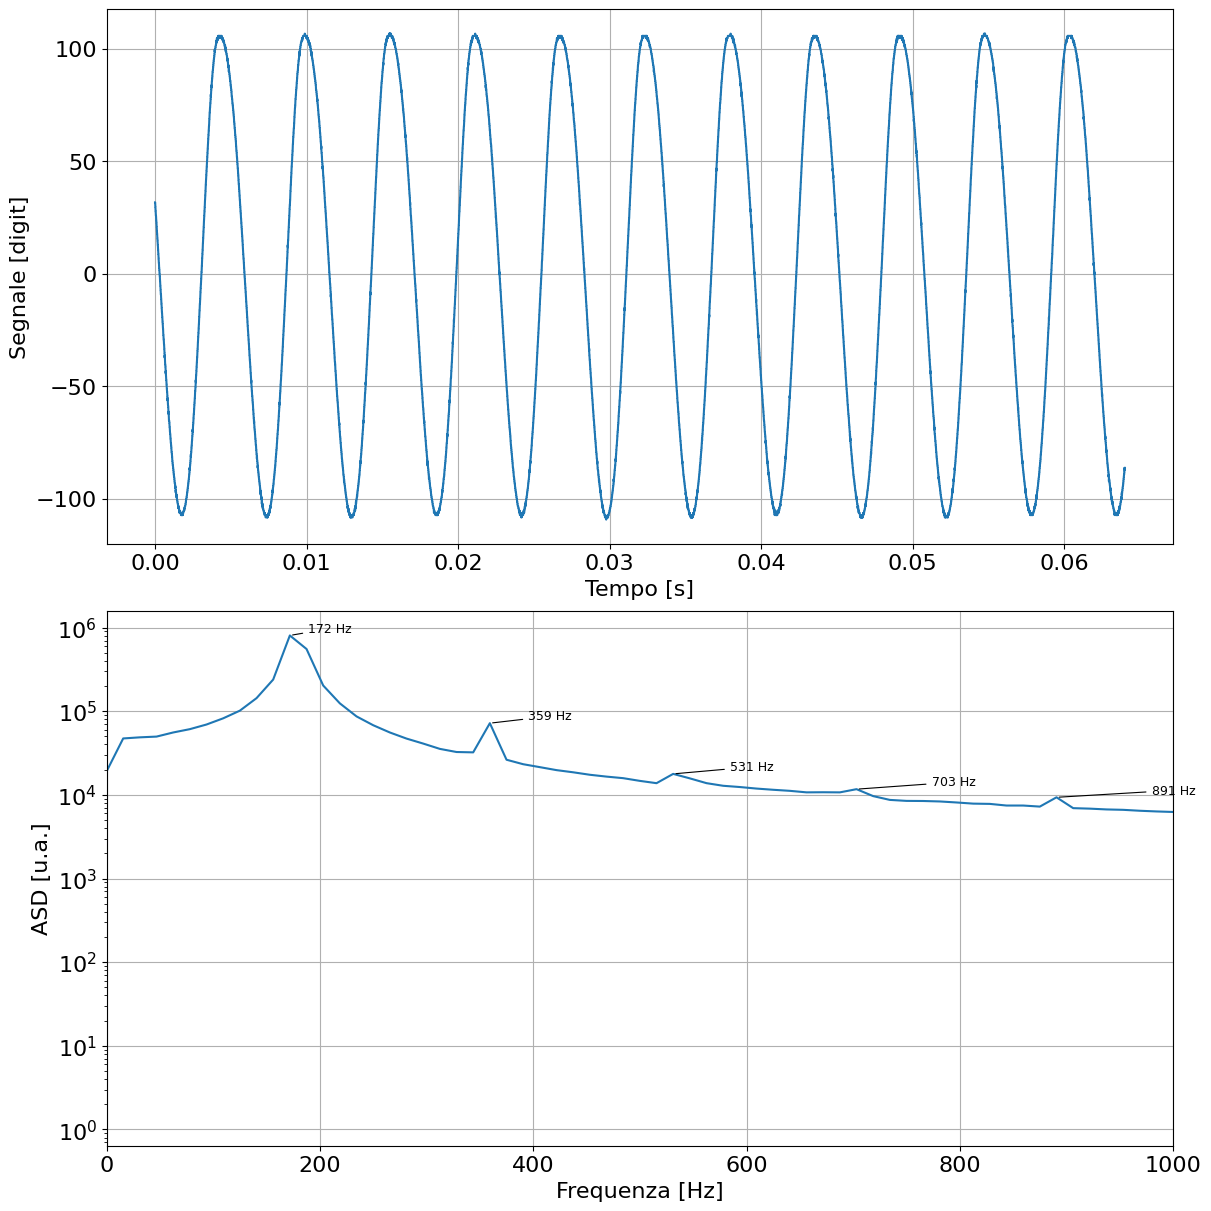

In [248]:
file = dir+'11/Segnali_autooscillatore/data_autooscillatore_2_CH2.txt'
idx = [0,1,2,4,6]
maxf = 1000
do_all(file, Arduino=False, peak_idx=idx, maxf=maxf)

Peaks: 

171.86640624999998 606682.5809802241
359.35703125 257896.9190519237
531.2234374999999 141014.25086330934
718.7140625 71238.57828698329
890.5804687499999 49071.72792164633
937.4531249999999 5841.287875384379
1062.4468749999999 25017.815022110648
1140.5679687499999 673.4642796132829
1187.440625 671.666195122928
1249.9375 21890.378936070658
1312.4343749999998 1554.119862518804
1421.80390625 10318.618083117208
1609.2945312499999 6558.884150514231
1781.1609374999998 6550.010765659081
1843.6578124999999 871.1452593970525
1890.53046875 874.776961075951
1968.6515625 3331.944295775507
2031.1484374999998 1183.788669038936
2078.0210937499996 1162.95971030226
2140.51796875 2074.8248951417745
2187.390625 962.8203763547489
2234.2632812499996 1071.4372897877151
2312.3843749999996 2081.428826229583
2390.5054687499996 981.9682952921031
2437.3781249999997 857.0025999058516
2499.875 1746.4690623273796
2562.371875 850.2464040405148
2624.8687499999996 826.180849174059
2702.9898437499996 866.832274

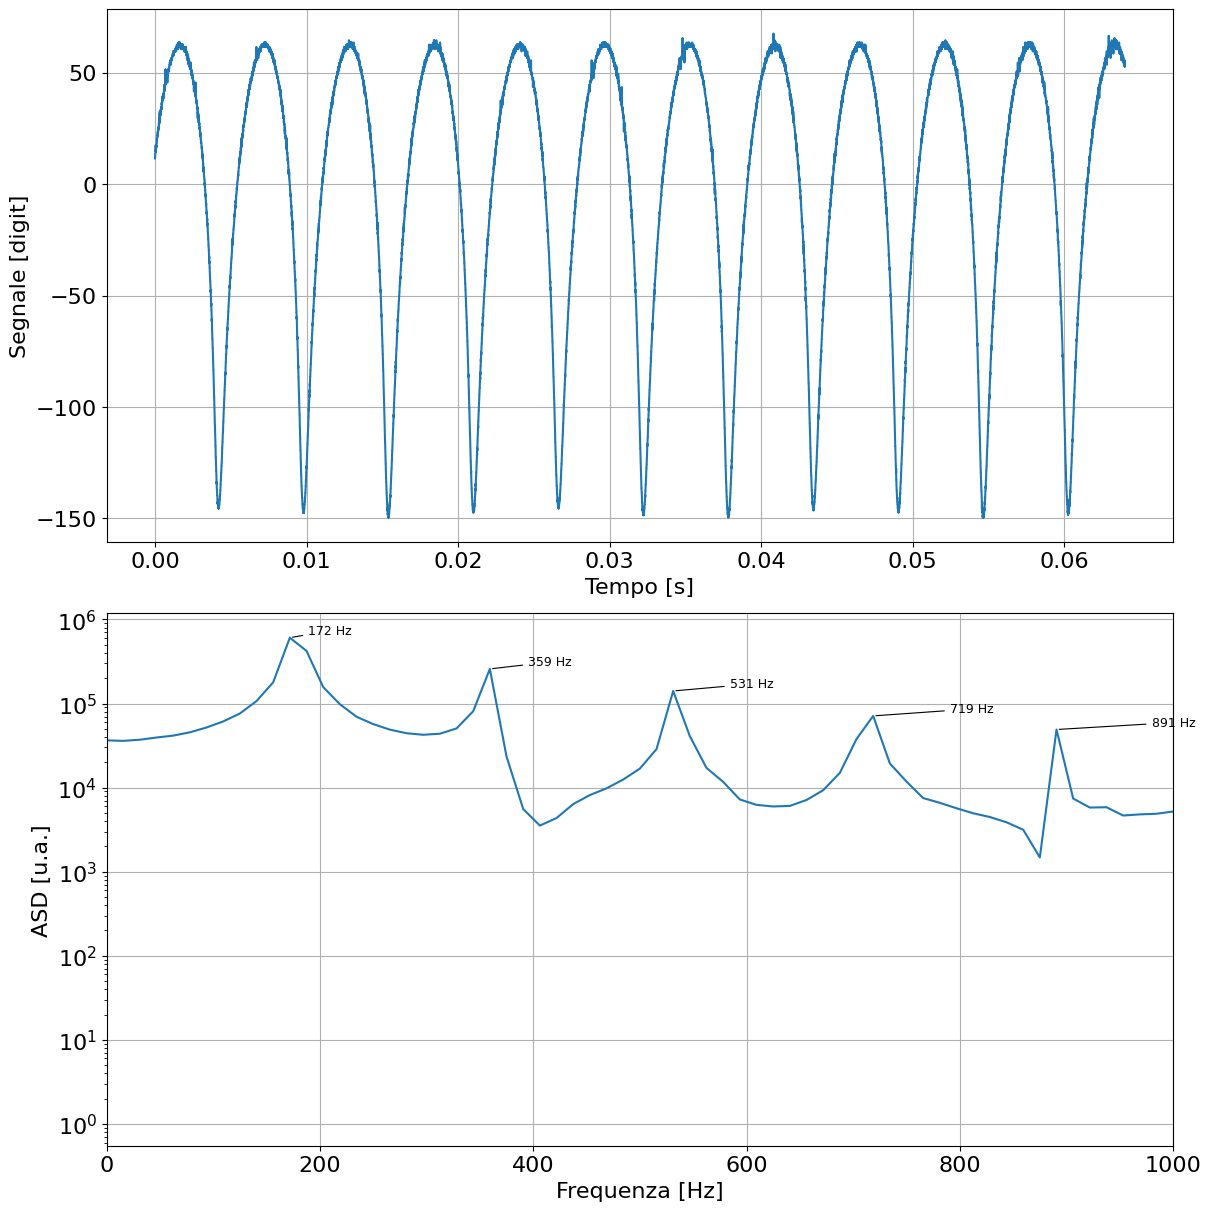

In [249]:
file = dir+'11/Segnali_autooscillatore/data_autooscillatore_2_CH1.txt'
idx = [0,1,2,3,4]
maxf = 1000
do_all(file, Arduino=False, peak_idx=idx, maxf=maxf)

**Spiegazione**

Sistema con:  
feedback positivo  
alimentazione  
-> genera oscillazioni da solo

🔴 Perché compaiono armoniche?  
L’oscillazione cresce → poi si stabilizza grazie a non linearità  
👉 il segnale NON è sinusoidale perfetto  
(es: clipping → tipo onda quadra)  
NON CAPISCO  

🔴 Larghezza del picco  
Molto importante:  
oscillatore ideale → picco infinitamente stretto
reale → picco con larghezza  
👉 dovuta a:  
rumore
instabilità
fluttuazioni

La larghezza del picco è indicativa della stabilità dell’oscillatore, mentre le armoniche riflettono eventuali non linearità.  
Lo spettro mostra un picco centrato sulla frequenza propria del circuito, la cui larghezza è legata allo smorzamento. Un maggiore smorzamento corrisponde a una distribuzione più larga in frequenza.  
perchè la larghezza del picco corssiponde allo smorzamento??? c'è smorzamento???


| Osservazione  | Significato             |
| ------------- | ----------------------- |
| picco stretto | oscillatore stabile     |
| picco largo   | instabilità             |
| armoniche     | distorsione non lineare |


Lo spettro del segnale mostra un picco centrato sulla frequenza di oscillazione del sistema. La presenza di armoniche indica che il segnale non è perfettamente sinusoidale, a causa delle non linearità che limitano l’ampiezza dell’oscillazione. La larghezza del picco è associata alla stabilità dell’oscillatore: un picco più largo indica maggiori fluttuazioni della frequenza dovute a rumore e instabilità del sistema.

#### Oscillatore smorzato RLC

**NOta**

qui non mettere l'asse y log  
perchè l'indicazione della freq è così strana e lontana?

Peaks: 

124.99374999999999 331.99945301513003
249.98749999999998 212.42858704286235
437.478125 157.539641204077
624.96875 86.54190620259486
937.4531249999999 70.28186342376763
1124.94375 53.20037602386236
1437.428125 55.942155897625184
1749.9125 67.15271068672276
2187.390625 31.48487154354068
2374.88125 41.948821300188165
2562.371875 45.827404807747115
2749.8624999999997 45.34206522779654
2937.3531249999996 42.28649411444461
3062.3468749999997 43.9453635412273
3249.8374999999996 42.41578806652059
3374.8312499999997 30.04032685401247
3687.3156249999997 27.523605705151194
3874.8062499999996 21.796563446037663
3999.7999999999997 41.87969141174047
4187.290625 27.33412417854619
4312.284374999999 18.846665317559868
4437.278125 49.82583835246931
4624.768749999999 27.46123265078609
4812.259375 28.774044395981576
4937.253124999999 22.990541877861954
5062.246875 30.33175013322538
5312.234375 30.36453788957511
5499.724999999999 27.018132586222347
5624.71875 24.14346115529115
5874.706249999999 21

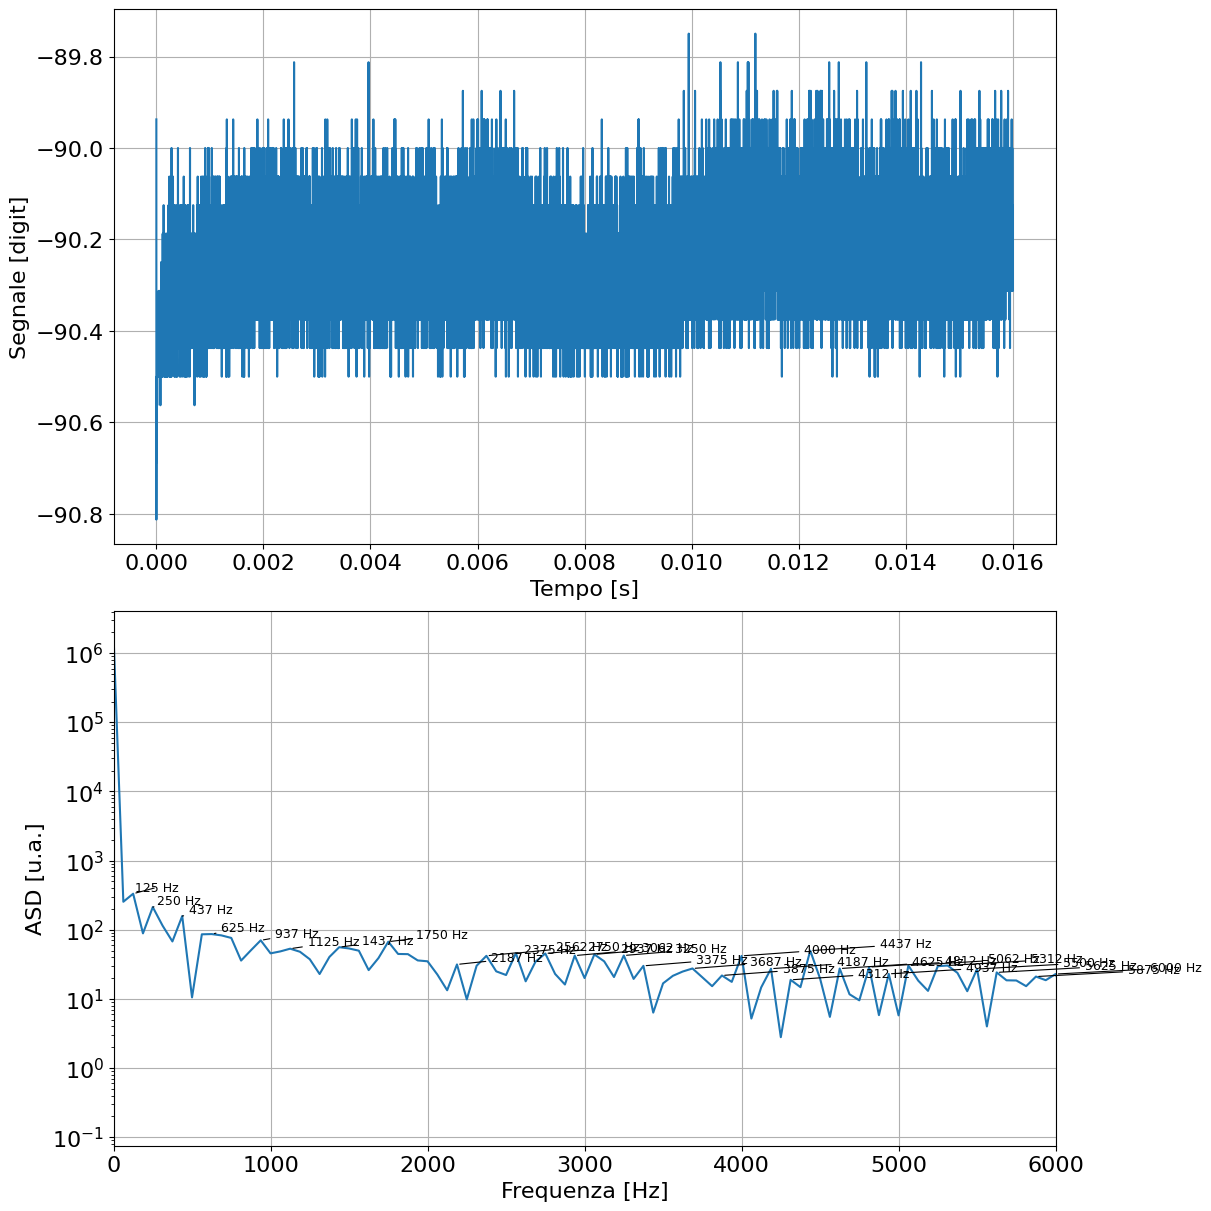

In [250]:
file = dir+'12/oscillatore_RLC_alluminio_profilato_segato_M_CH2.txt'
idx = None  # come togliere gli indici???
maxf = 6000
do_all(file, Arduino=False, peak_idx=idx, maxf=maxf)

Peaks: 

1061.9687500000002 48011.768288363826
3123.4375000000005 317.4039140616939
3248.3750000000005 269.6459893736295
3873.0625000000005 192.06257787652086
4247.875000000001 152.56038062601226
4435.281250000001 150.8064647179467
4560.218750000001 138.93127361905468
4747.625000000001 121.17345977905502
4872.562500000001 122.17164041671562
5122.437500000001 117.45640133714049
5247.375000000001 111.70875209108704
5434.781250000001 98.19495666674781
5559.718750000001 92.93873647354165
5809.593750000001 86.1061717935652
6059.468750000001 72.30079384072914
6246.875000000001 70.60976760494006
6371.812500000001 73.17452532106468
6684.156250000001 71.53041922775245
6809.093750000001 65.42127027378004
6934.031250000001 64.85656769132771
7058.968750000001 69.19487542598883
7246.375000000001 62.93454593057195
7433.781250000001 53.54778582973493
7558.718750000001 51.76454753856868
7746.125000000001 45.19305992129753
7996.000000000001 49.923466002118936
8245.875000000002 49.04070491434791
8370.81

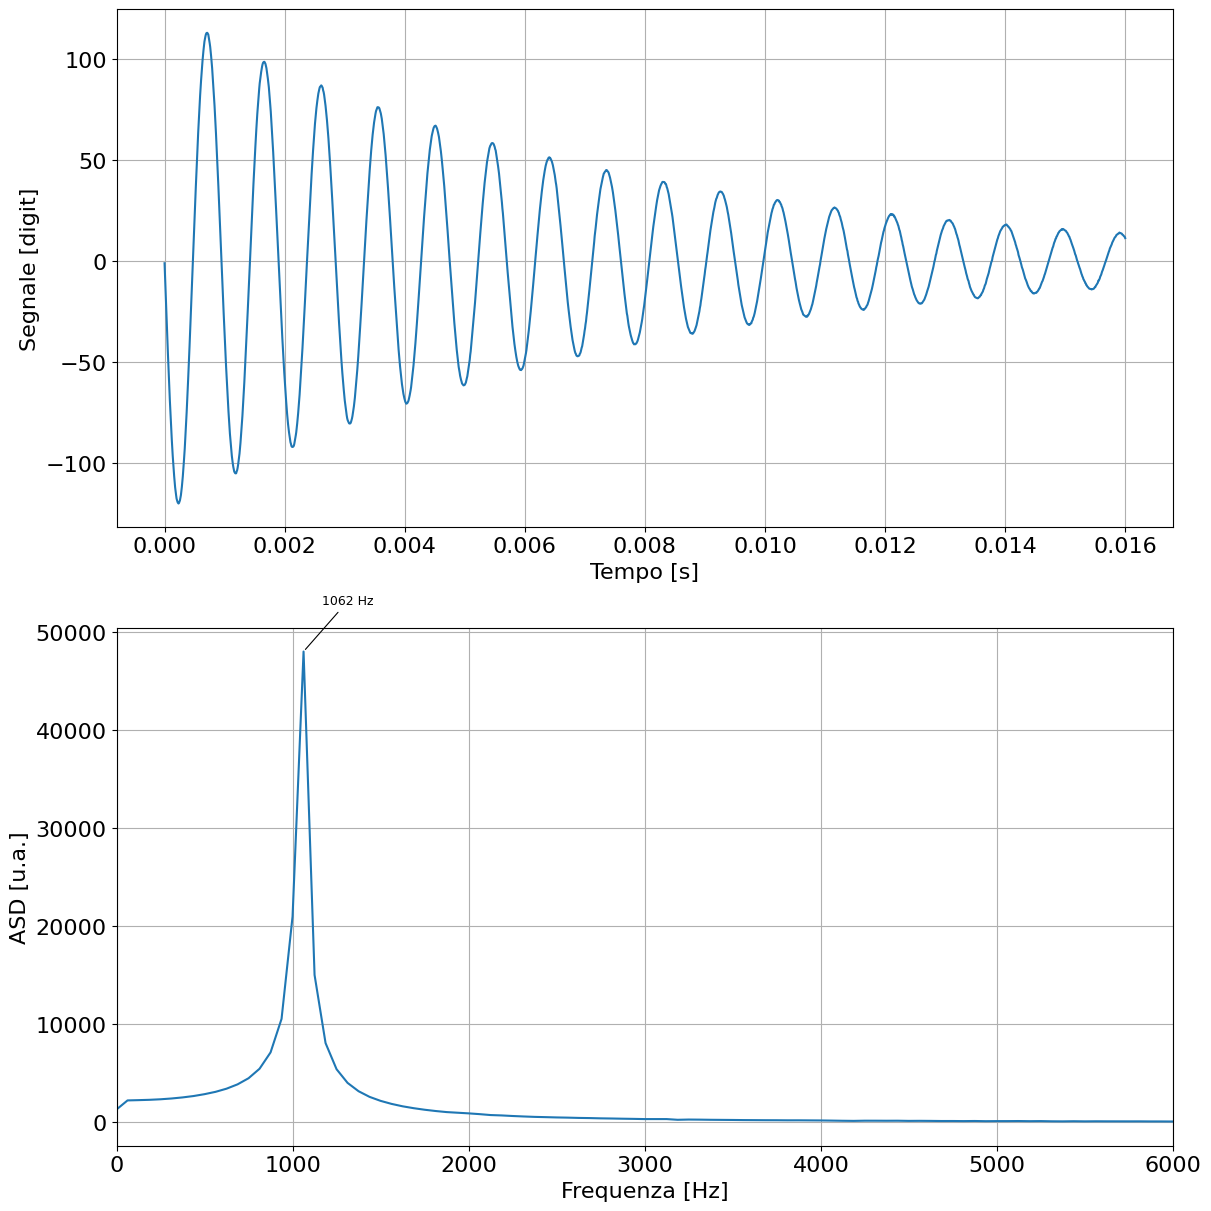

In [251]:
# Vuoto

file = dir+'12/RLC_normale_C1_M_CH1.txt'
idx = [0]
maxf = 6000
do_all(file, Arduino=False, peak_idx=idx, maxf=maxf, log=False)

Peaks: 

874.95625 140595.98860923425
3999.7999999999997 1852.8174364192805
4312.284374999999 1520.2154042464215
4562.271874999999 1402.8085236227794
4687.265625 1328.7702007557343
4812.259375 1271.035956867156
5187.240624999999 1027.2142908851904
5499.724999999999 871.5918155343178
5687.215625 872.6594350495815
5812.209374999999 871.980141495783
5937.203125 850.1227364664998
6124.693749999999 785.9869132389363
6499.674999999999 626.2333922795351
6624.66875 636.6181668111856
6937.153125 571.708580916118
7062.146874999999 590.6202283349297
7249.6375 580.834721280381
7437.128124999999 546.1914703942873
7749.612499999999 484.83407123334695
7937.103125 453.8942392397133
8062.096874999999 411.8453945103312
8187.090625 428.78796209065905
8374.58125 423.2750832396864
8687.065625 349.04705819439744
8812.059374999999 375.28419706266084
8999.55 389.7993949613404
9374.53125 311.31209538171464
9562.021874999999 296.4974159272461
9687.015625 325.8051036117203
9812.009375 305.5104795137515
9999.5 29

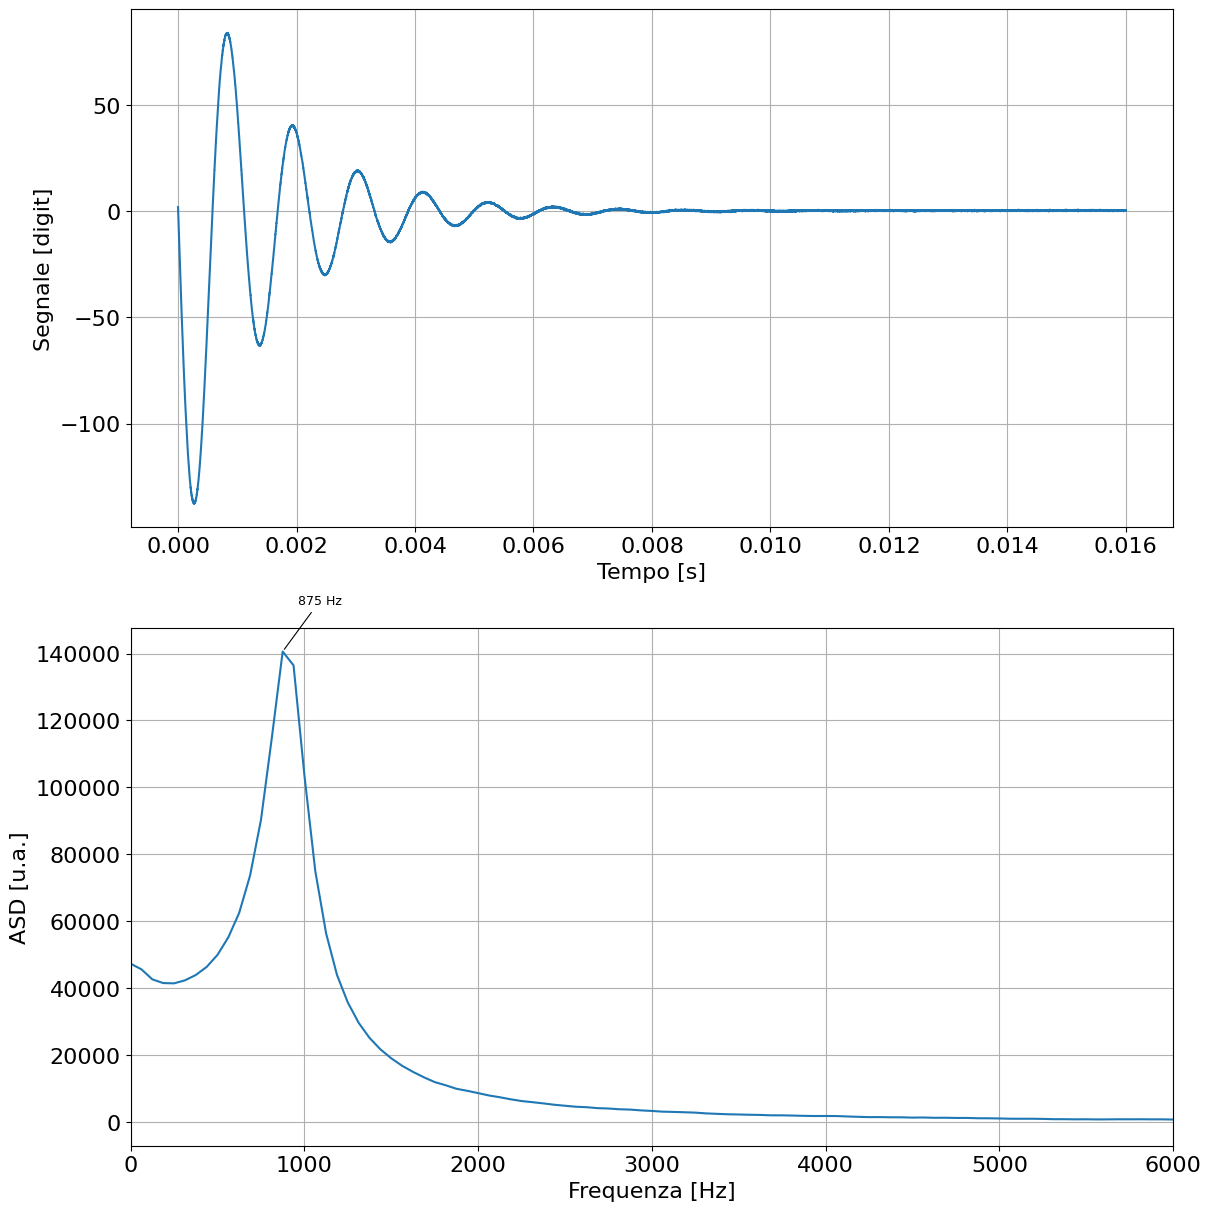

In [252]:
# Oscillatore smorzato RLC

file = dir+'12/oscillatore_RLC_ferro_pieno_v2_M_CH1.txt'
idx = [0]
maxf = 6000
do_all(file, Arduino=False, peak_idx=idx, maxf=maxf, log=False)

**Spiegazione segnale in ingresso**

è un segnale in DC, minore di 0  
perchè è la semionda negativa dell'onda quadra (quella durante il quale il circuito è libero di oscillare)

**Spiegazione segnale in uscita**

Contesto:  
Segnale pseudo-periodico (non infinito nel tempo)

1- vuoto:  
$\omega = 6617$, quindi $f_0=1053$  
incertezza??? e unità di misura???    
$\tau = 0.007$  
la FFT mi dà f=1062  

2- ferro pieno
$\omega = 5677$, quindi $f_0 =903$   
$\tau = 0.0.0014$  
la FFT mi dà f=875  

**Spiegazione**

c'è un unico picco  

1- centrato in f0  
$f_0=\frac 1 { 2 \pi \sqrt{LC}}$   

2- Larghezza dipende dallo smorzamento   
$\Delta f \sim \frac RL$ (è giusta??? di cosa è??)
più smorzamento → picco più largo  
infatti se non fosse smorzato, ma fosse una sinusoide ideale, il suo spettro avrebbe solo la frequenza f0  
infatti col ferro è più smorzato, quindi vedo picco più largo  

**Scritta bene**

A differenza dei segnali periodici, lo spettro dell’oscillatore smorzato non presenta picchi discreti ma una distribuzione continua centrata sulla frequenza propria del circuito. La larghezza del picco è direttamente legata allo smorzamento: un decadimento più rapido nel tempo corrisponde a una maggiore dispersione in frequenza.

oscillatore_RLC_vuoto_M_CH1.txt : 
 omega = 6616.598600200468 + 3.7766283402281274e-05 
 tau = 0.007085621515808751 
 Q + 23.44135670152525 

oscillatore_RLC_alluminio_pieno_M_CH1.txt : 
 omega = 7033.788812648596 + 0.00017378609732616196 
 tau = 0.004079548216139191 
 Q + 14.34734030167019 

oscillatore_RLC_alluminio_profilato_M_CH1.txt : 
 omega = 6919.646450432512 + 0.00018182621502601227 
 tau = 0.004006483980452042 
 Q + 13.861726327024849 

oscillatore_RLC_alluminio_profilato_segato_M_CH1.txt : 
 omega = 6625.437668976078 + 4.9244498023948346e-05 
 tau = 0.006483479959904746 
 Q + 21.47794617620221 

oscillatore_RLC_ferro_pieno_v2_M_CH1.txt : 
 omega = 5676.642997604881 + 0.0021304052735326255 
 tau = 0.0013956318242537929 
 Q + 3.9612518111924095 

oscillatore_RLC_ferro_laminato_M_CH1.txt : 
 omega = 4242.758009886617 + 3.186139045206715e-05 
 tau = 0.006586871300824439 
 Q + 13.973250485832587 



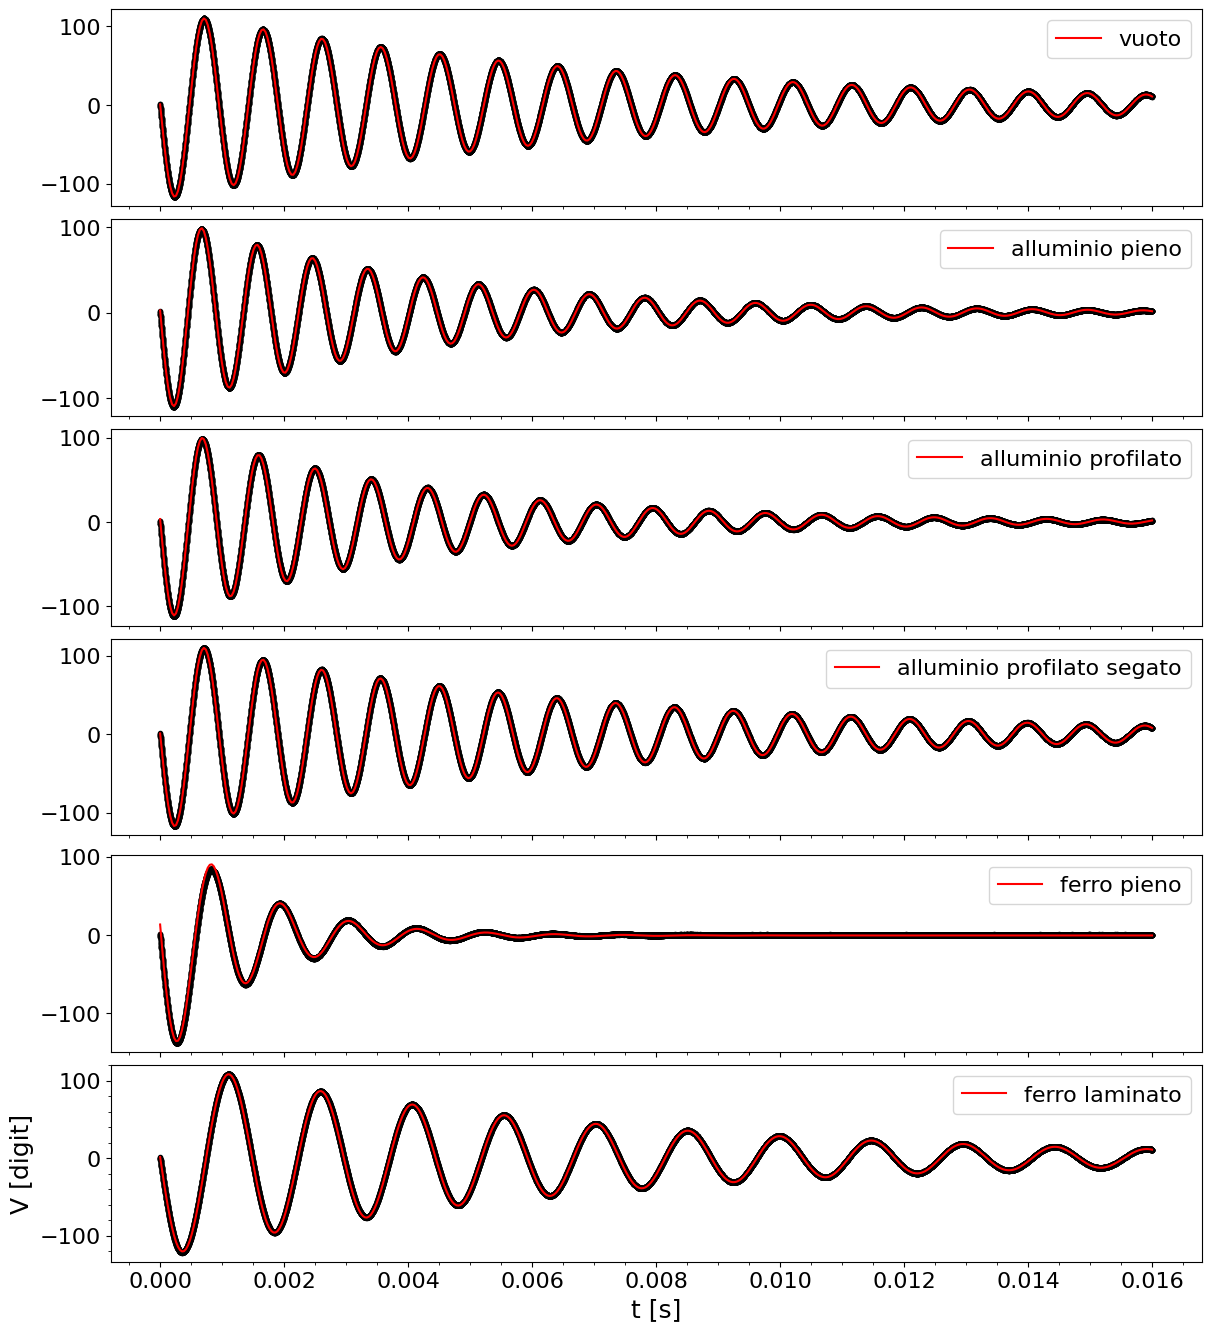

In [253]:
import pylab
import numpy
from scipy.optimize import curve_fit


Directory='/home/gea/Desktop/Lab_2/AliceGea/Esperienza_12/' # <<<<<< now looking at a file in the datifit directory
file1 = 'oscillatore_RLC_vuoto_M_CH1.txt'   # <<<<<< now looking at a file called data00.txt
file2 = 'oscillatore_RLC_alluminio_pieno_M_CH1.txt'
file3 = 'oscillatore_RLC_alluminio_profilato_M_CH1.txt'
file4 = 'oscillatore_RLC_alluminio_profilato_segato_M_CH1.txt'
file5 = 'oscillatore_RLC_ferro_pieno_v2_M_CH1.txt'
file6 = 'oscillatore_RLC_ferro_laminato_M_CH1.txt'

files = [file1, file2, file3, file4, file5, file6]
labels = ['vuoto', 'alluminio pieno', 'alluminio profilato', 'alluminio profilato segato', 'ferro pieno', 'ferro laminato']

fig, axes = pylab.subplots(nrows=6, ncols=1, constrained_layout=True, figsize = (12,2.2*6), sharex=True)

for ax, file,i in zip(axes, files, range(6)):
    Filename = Directory+file
    x,Dx,y,Dy=pylab.loadtxt(Filename,unpack=True)  # <<<<< the file is assumed to have 4 columns
    ax.errorbar(x,y,Dy,Dx,linestyle = '', color = 'black', marker = '.', zorder=1)

# bellurie
    pylab.rc('font',size=16)
    pylab.xlabel('t [s]',fontsize=18)
    pylab.ylabel('V [digit]',fontsize=18)
    pylab.minorticks_on()


# AT THE FIRST STEP (data plot only) YOU MUST COMMENT FROM HERE TO THE LAST LINE (pylab.show())

# make the array with initial values (to be carefully adjusted!)
    init=(1, 728e-1, 0.010, 6900, 1.55)

# set the error (to be modified if effective errors have to be accounted for)
    sigma=Dy
    w=1/sigma**2

# define the model function (a straight line in this example)
# note how parameters are entered
# note the syntax
    def ff(t, off, A, tau, omega, phi):
        return off + A * numpy.exp(-t/tau)*numpy.cos(omega * t +phi)


# AT THE SECOND STEP (plot of the model with initial parameters):
# YOU MUST COMMENT FROM HERE TO THE THIRD TO LAST LINE
# (AND PUT IN THAT LINE *init IN THE PLACE OF *pars)
# call the routine


    pars,covm=curve_fit(ff,x,y,init,sigma,absolute_sigma=True) # <<<< NOTE THE absolute_sigma option

# calculate the kappasquare for the best-fit funtion
# note the syntax for the pars array
    kappa2 = ((w*(y-ff(x,*pars))**2)).sum()

# determine the ndof
# print results on the console
    print(f'{file} : \n omega = {pars[3]} + {covm[3][3]} \n tau = {pars[2]} \n Q + {pars[3]*pars[2]/2} \n')

# AT THE SECOND STEP, COMMENT UP TO HERE
# prepare a dummy xx array (with 500 linearly spaced points)
    xx=numpy.linspace(min(x),max(x),500)

# plot the fitting curve with either the initial or the optimised parameters
# AT THE SECOND STEP, YOU MUST REPLACE *pars WITH *init
    ax.plot(xx,ff(xx,*pars), color='red', zorder=2, label = labels[i])
    ax.legend(loc='upper right')

# show the plot
pylab.show()

### Use code

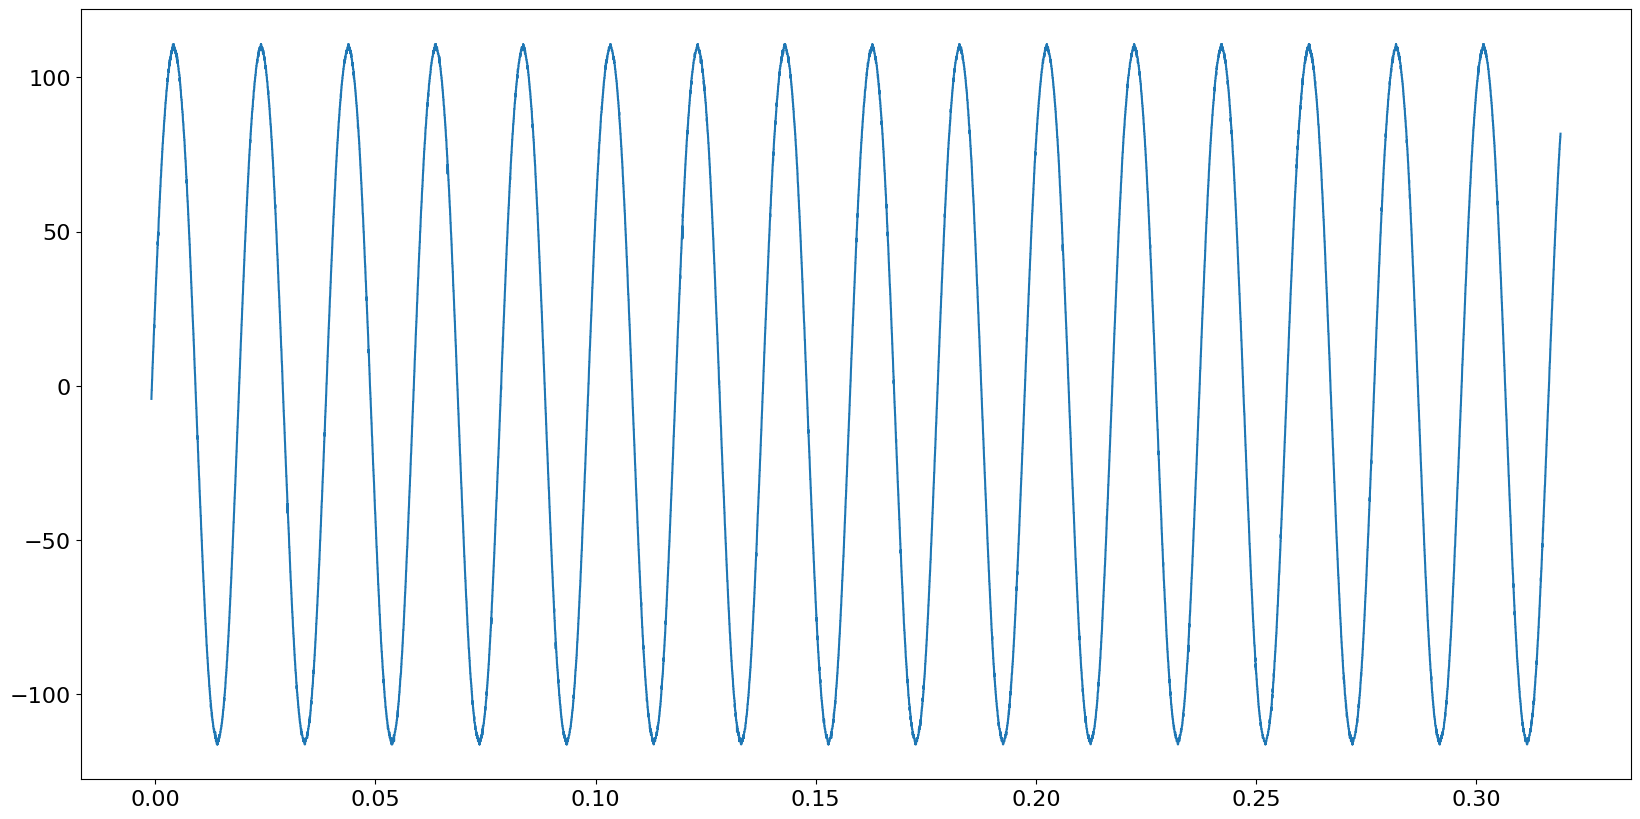

In [254]:
# Check

file = dir+'9/Livellatore/livellatore_senza_condensatore_CH1.txt'
t,V = input_data(file)
plt.figure(figsize=(20, 10))
plt.plot(t,V)


Peaks: 

49.99750000000008 1089494.1147565972
99.99500000000016 21261.335664404498
106.24468750000017 9491.229489285626
153.11734375000026 7730.0648900716615
193.7403125000003 5097.811680838758
199.99000000000032 5403.429271836556
209.36453125000034 4145.409320755623
228.11359375000038 3973.57480289149
234.36328125000037 3864.979188990574
240.6129687500004 3703.3498294028414
253.1123437500004 3704.6072746346813
287.4856250000005 3055.492455564602
303.1098437500005 4295.463552133112
315.6092187500005 2827.095351808002
331.23343750000055 2732.4693946296693
343.73281250000053 2576.2653315329153
353.10734375000055 4001.001033008622
368.7315625000006 2385.3768026701955
378.1060937500006 2299.698921819616
387.4806250000006 2292.4028825221158
393.73031250000065 2327.7773526131314
406.22968750000064 2210.231165005393
415.60421875000065 2138.5466497002544
437.4781250000007 2000.1168685290716
456.22718750000075 2121.956323661978
474.9762500000008 1861.8590798181992
481.2259375000008 1923.5101693

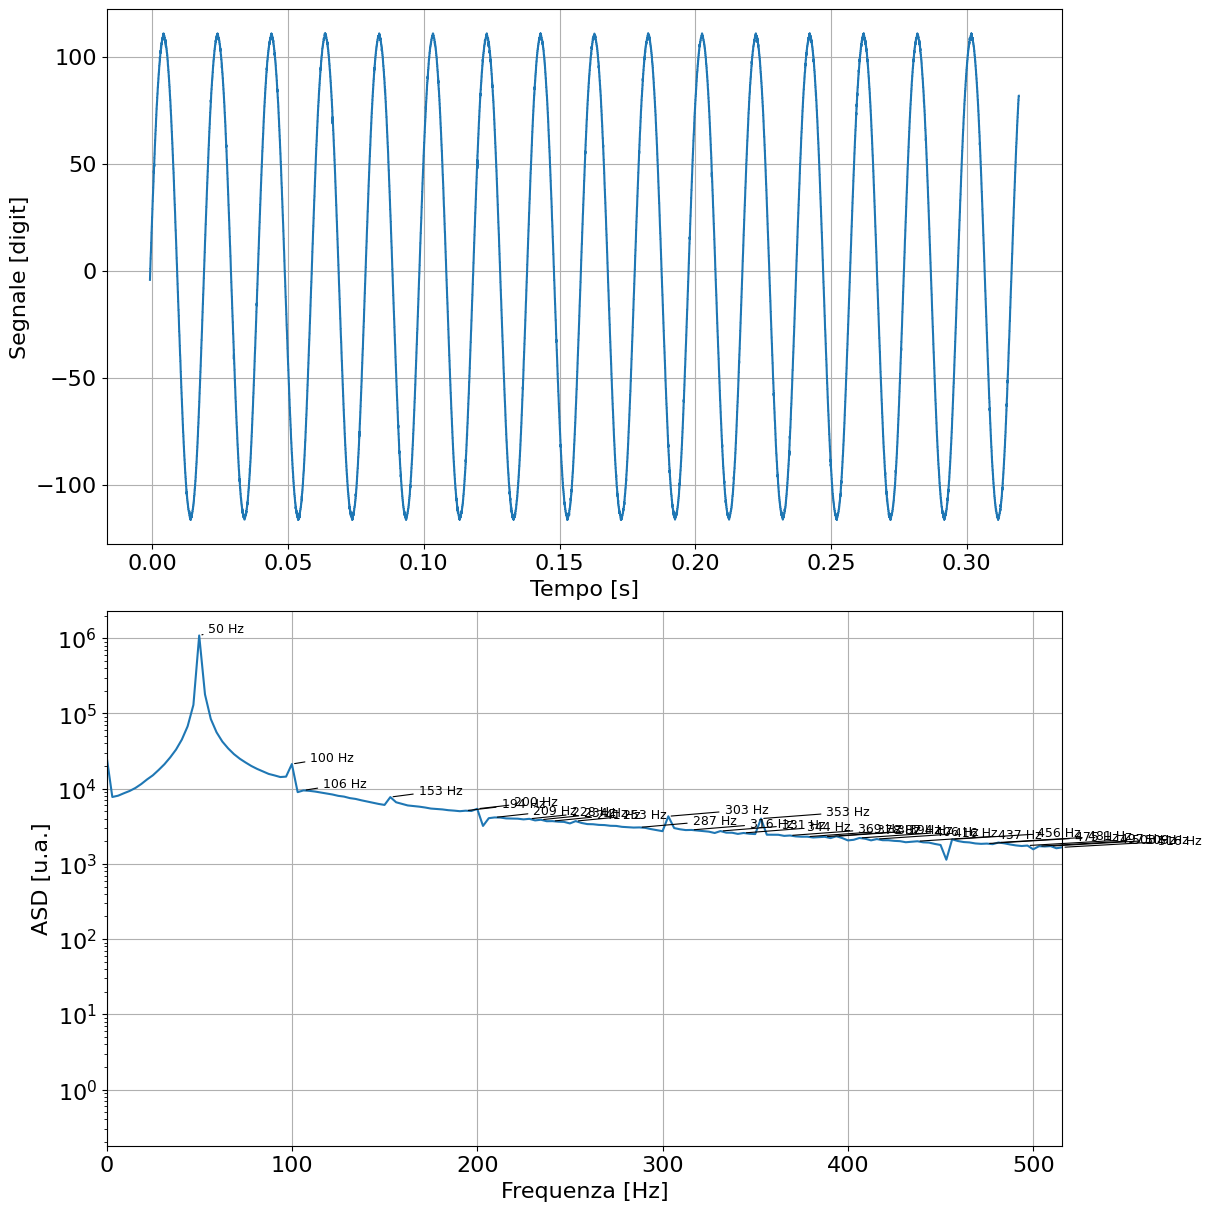

In [255]:
do_all(file, Arduino=False)

### Interpretare

mi servono freq e ASD dei picchi

**Casi**

solo un picco a f0: sinusoidale pura
solo armoniche dispari, con ampiezza A_n sim 1/n: quadra
solo armoniche dispari, con ampiezza A_n sim 1/n^2: triangolare
tutte le armoniche, ampiezza 1/n:pinna di squalo

| Segnale     | Armoniche presenti | Decadimento |
| ----------- | ------------------ | ----------- |
| Sinusoide   | solo (f_0)         | —           |
| Quadra      | solo dispari       | (1/n)       |
| Triangolare | solo dispari       | (1/n^2)     |
| Sawtooth    | tutte              | (1/n)       |


### Aliasing

Aliasing = campionare troppo lentamente → confondere una frequenza alta con una più bassa

👉 Il segnale viene “visto male” perché lo guardi troppo di rado.

👀 Intuizione visiva (tipo film)

Immagina una ruota che gira veloce:

se la filmi bene → vedi la rotazione giusta
se fai pochi frame → sembra:
più lenta
ferma
addirittura al contrario

👉 Questo è aliasing.

⚙️ Nel tuo caso

Hai:

t = np.linspace(0, 1000, 1000)

👉 quindi:

Δt ≈ 1 s
frequenza di campionamento:
fs=1 Hz
f
s
	​

=1 Hz

👉 limite massimo misurabile (Nyquist):

fmax=fs2=0.5 Hz
f
max
	​

=
2
f
s
	​

	​

=0.5 Hz
❗ Ma il tuo segnale è:
f=52π≈0.8 Hz
f=
2π
5
	​

≈0.8 Hz

👉 cioè più alto del massimo misurabile

💥 Cosa succede (aliasing)

La FFT “non può rappresentarlo” correttamente
➡️ quindi lo ripiega dentro l’intervallo valido

Formula pratica:

falias=∣f−nfs∣
f
alias
	​

=∣f−nf
s
	​

∣

Nel tuo caso:

falias=∣0.8−1∣=0.2 Hz
f
alias
	​

=∣0.8−1∣=0.2 Hz

✅ Risultato

Vedrai un picco a:

👉 0.2 Hz invece di 0.8 Hz

🔥 Regola d’oro (Nyquist)

Per evitare aliasing:

fs>2fsegnale
f
s
	​

>2f
segnale
	​


👉 cioè devi campionare almeno il doppio

### Simulazioni

**Nota**

$\omega = 2 \pi f$  
$f =\omega /(2 \pi)$  

esempio:  
$f = 5 /(2 \pi) = 0.8$ 

In [256]:
# Sinusoidale

t =np.linspace(0, 10, 1000)
V = 10* np.sin(5*t)

freq, ASD = do_FFT(t,V)
peak_freqs= peaks(freq, ASD)
plot_ASD(t,V,freq,ASD, peak_freqs)

Peaks: 

0.7992 5000.683290508231


TypeError: plot_ASD() missing 2 required positional arguments: 'peak_idx' and 'maxf'

**Osservazioni: sin**

ha un solo picco, alla freq fondamentale  

Peaks: 

0.7992 6353.83831356703
1.4985 61.7899984051537
2.3976 2085.179031037854
3.0969 62.20332531098365
3.996 1212.3950366310864
4.6953000000000005 61.677063156809375
5.5944 825.5904729267551
6.2937 60.26683782974928
6.793200000000001 87.23250017884361
7.1928 601.7485168135973
7.8921 58.05525078813039
8.3916 84.70016250754487
8.7912 452.99762415432656
9.4905 55.1490030914952
9.99 80.81147918767299
10.3896 345.70364371952587
11.0889 51.67554206212111
11.5884 75.6622527168778
11.8881 277.45122463868717
12.287700000000001 48.792280215296074
12.6873 47.779436207477126
13.1868 69.39231110369357
13.4865 276.4269420604969
13.8861 45.040122060085096
14.2857 43.6186970494049
14.7852 62.18683050129439
15.084900000000001 272.82607445342376
15.4845 42.030880989415586
15.8841 39.361212450442395
16.3836 54.28096454653984
16.6833 266.7305815918158
17.082900000000002 39.737101378977016
17.4825 35.1812348567893
17.982 45.973005969296544
18.2817 258.27468075576957
18.6813 38.03394211994876
19.0809 31

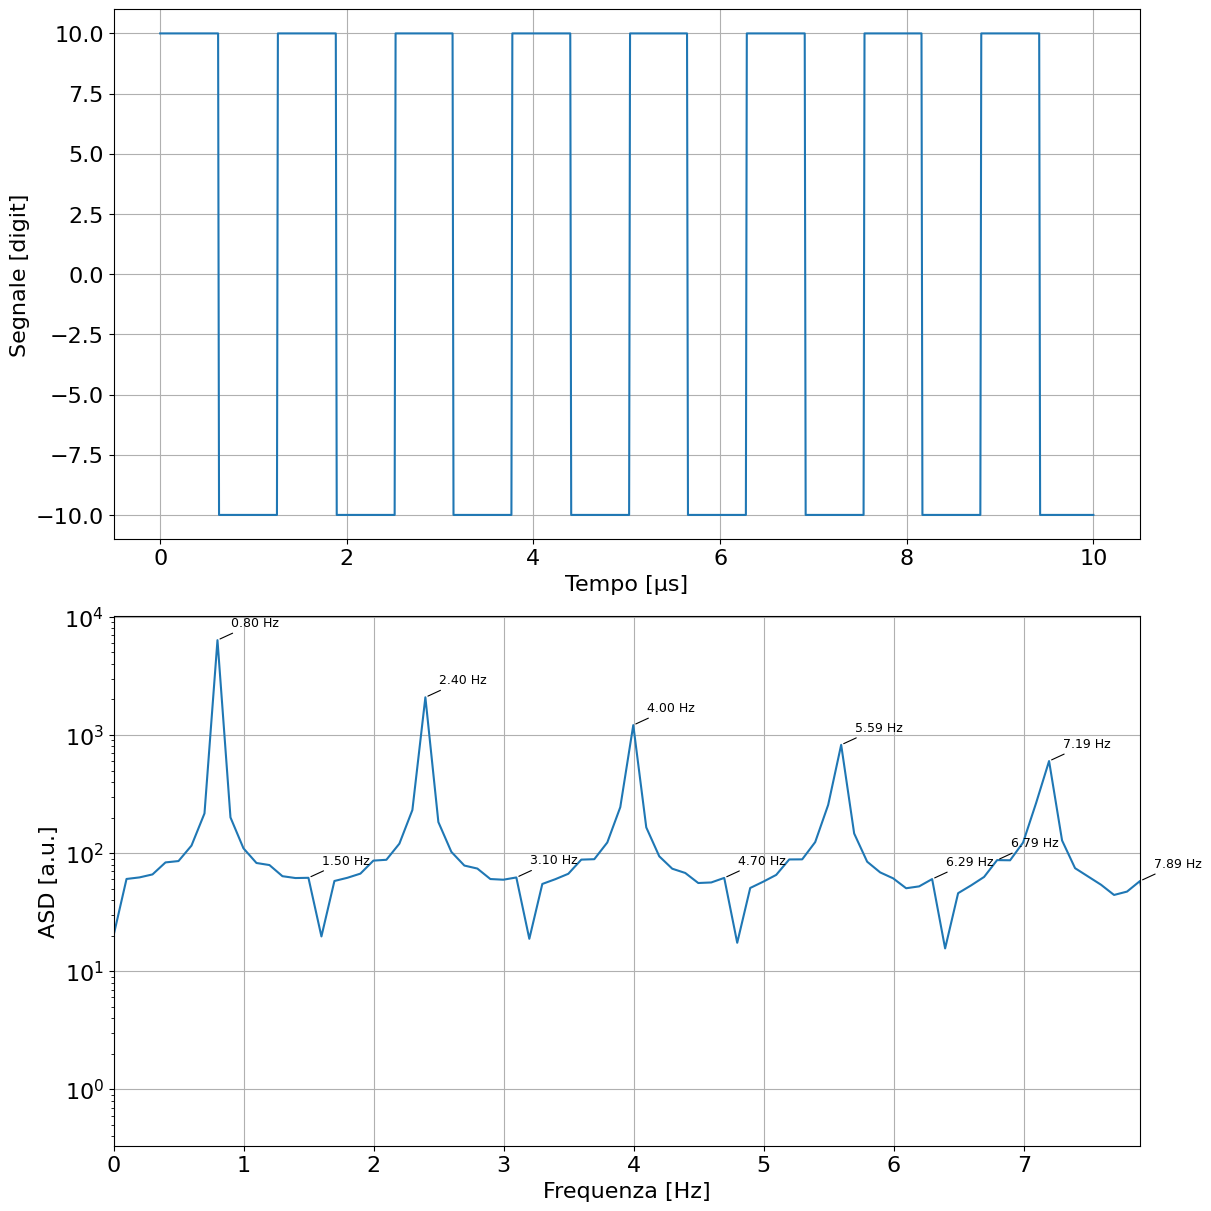

In [ ]:
# Quadra

from scipy import signal

t = np.linspace(0, 10, 1000)
omega = 5
A = 10

V_square = A * signal.square(omega * t)

freq, ASD = do_FFT(t, V_square)
peak_freqs = peaks(freq, ASD)
plot_ASD(t, V_square, freq, ASD, peak_freqs)

**Osservazioni: quadra**

che picchi vede:  
solo le armoniche dispari, f0, 3 f0, 5 f0...  
cioè: 0.8, 2.4, 4.0 ...

ampiezza:  
6300, 2080, 1200...
cioè decresce come 1/n
cioè 2000=6000/3, 1200 = 6000/5...

Peaks: 

0.7992 4031.202601718816
2.3976 444.0658388238748
3.996 157.0112174591086
5.5944 77.82811424656701
7.1928 45.14916055099806
8.7912 28.52708788486651
9.99 2.1338672422385363
10.3896 18.906371387381352
11.5884 2.222707167233842
11.988 12.83284458902127
13.1868 2.2202900388604303
13.4865 9.308806736655859
14.7852 2.1431390746502217
15.084900000000001 8.507293481002739
16.3836 2.0066813050977728
16.6833 7.8316874187413275
17.5824 1.7250676084582466
17.982 1.8253018093801225
18.2817 7.230530203844563
18.6813 1.6798071657543003
19.1808 1.5216934456933318
19.5804 1.6130388853749402
19.8801 6.670404656680307
20.279700000000002 1.4470558410905872
20.7792 1.3408077391973303
21.1788 1.3844267761680633
21.4785 6.13033133581801
21.6783 1.0893614827698166
21.8781 1.2877890025140588
22.3776 1.1884668463897796
22.7772 1.1556770524886812
23.076900000000002 5.598152682213783
23.4765 1.1883033567813208
23.976 1.0686516290558017
24.2757 1.042727482468919
24.6753 5.068061352839196
25.0749 1.130242

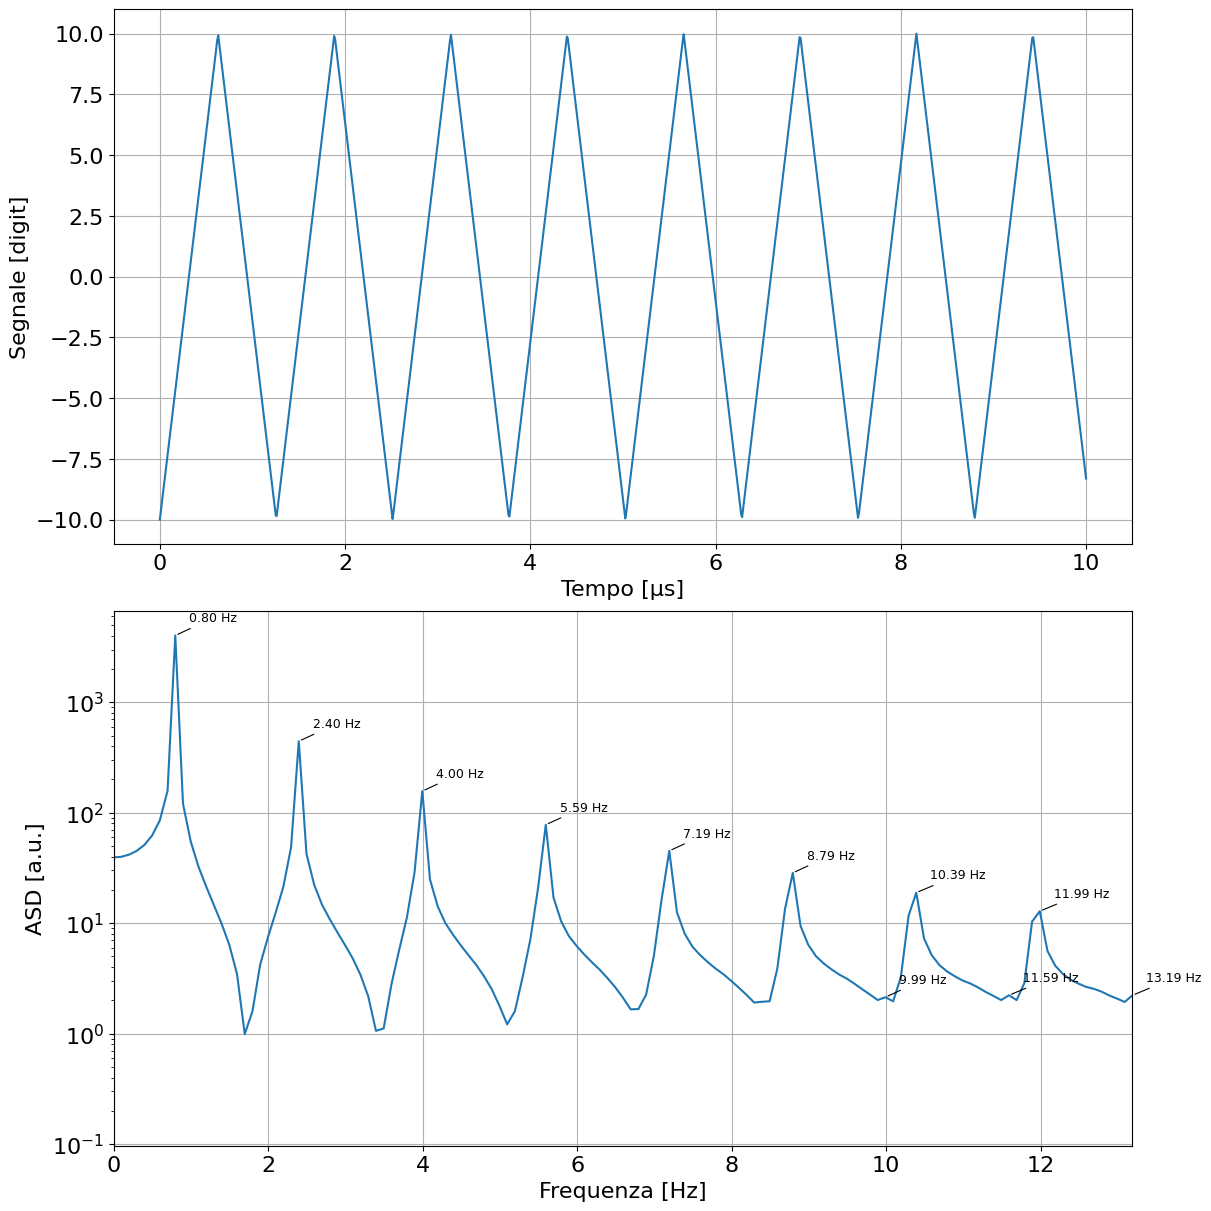

In [ ]:
# Triangolare

t = np.linspace(0, 10, 1000)
omega = 5
A = 10

V_triangle = A * signal.sawtooth(omega * t, width=0.5)

freq, ASD = do_FFT(t, V_triangle)
peak_freqs = peaks(freq, ASD)
plot_ASD(t, V_triangle, freq, ASD, peak_freqs)

**Osservazioni: triangolare**

che picchi vedo: 
solo i dispari, come nella quadra  

ampiezza:  
4000, 444, 157...
cioè: 444=4000/9, 157 = 4000/25
scala come 1/n^2